# Can K-Food Demand Data Predict Korean Food Equities?
## Research-Grade Open-Source Pilot — Version 3 (October 2026)

### Abstract
This study tests whether observable Korean-food demand signals can forecast subsequent corporate fundamentals and equity performance.

The central result is deliberately conservative: **the economic thesis is credible, but annual public data do not yet establish robust sector-wide alpha.** The signal is more encouraging after 2022 and captures Samyang Foods particularly well, but the equity result weakens sharply when Samyang is removed and permutation tests do not reject a random-ranking null at conventional significance levels.

The correct next research stage is a monthly **U.S. K-Food Demand Nowcast** built from customs, retail distribution, digital attention and point-in-time market data.


# 1. Research design

**Primary question:** Can K-food demand at time *t* predict company revenue growth and equity excess returns at *t+1*?

**H1 — Fundamentals:** category demand should lead revenue growth for companies exposed to that category.

**H2 — Equity:** higher demand exposure should lead higher subsequent excess returns.

**H3 — Robustness:** any claimed signal should survive removal of Samyang, removal of the sauce series, modest exposure-weight perturbations, a momentum control and a permutation placebo.

A failure of these tests means the study does **not** claim an investable alpha.


# 2. Data hierarchy and integrity

**A:** government statistics or official company filings/IR.  
**B:** institutional market/financial database.  
**C:** press/private-company estimate; descriptive only.

Important integrity decisions:
- H Mart revenue is **not** backfilled into a historical time series because H Mart is private.
- Google Trends/TikTok/retail scanner series are **not fabricated**.
- Annual stock variations are price returns, not total returns.
- The sauce series is treated as lower-confidence because public definitions can differ; it gets an explicit exclusion test.


In [1]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr, pearsonr
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

cats=["broad","ramen","kimchi","rice","sauce"]
category=pd.DataFrame({
"year":[2019,2020,2021,2022,2023,2024,2025],
"broad":[7.03,7.57,8.56,8.89,9.16,9.98,10.41],
"ramen":[466.996,603.57,674.6,765.43,952.4,1248.5,1521.4],
"kimchi":[104.992,144.5,159.9,140.816,155.6,163.6,164.4],
"rice":[108.4,137.6,163.1,180.6,216.3,299.2,np.nan],
"sauce":[259,322,364,362,384,394,411.9]})
for c in cats:
    category[c+"_yoy"]=category[c].pct_change(fill_method=None)*100
    category[c+"_sig"]=np.tanh(category[c+"_yoy"]/20.0)
category["breadth"]=(category[[c+"_yoy" for c in cats]]>0).sum(axis=1)/category[[c+"_yoy" for c in cats]].notna().sum(axis=1).replace(0,np.nan)

exposure=pd.DataFrame({
"company":["Samyang Foods","Nongshim","CJ CheilJedang","Daesang","Ottogi","Pulmuone"],
"broad":[.07,.17,.58,.13,.25,.78],
"ramen":[.90,.80,.02,.02,.42,.08],
"kimchi":[0,0,.08,.40,.01,.01],
"rice":[0,0,.20,.02,.07,.10],
"sauce":[.03,.03,.12,.43,.25,.03]}).set_index("company")

returns=pd.DataFrame({
"year":[2020,2021,2022,2023,2024,2025],
"Samyang Foods":[12.35,-6.14,33.97,70.08,254.17,60.92],
"Nongshim":[24.74,6.17,12.09,14.01,-8.11,15.64],
"CJ CheilJedang":[50.89,1.71,-1.81,-14.85,-21.14,-18.59],
"Daesang":[12.28,-10.56,-6.01,-5.25,-7.52,9.69],
"Ottogi":[4.15,-20.97,4.39,-15.97,-1.13,-2.65],
"Pulmuone":[47.11,4.53,-35.26,-6.34,2.00,20.93],
"KOSPI":[30.54,3.69,-24.87,18.73,-9.63,75.63]})

sales=pd.DataFrame({
"year":[2021,2022,2023,2024,2025],
"Samyang Foods":[642.030,909.037,1192.915,1728.015,2351.785],
"Nongshim":[2662.983,3129.065,3410.6,3438.731,3514.316],
"CJ CheilJedang":[9566.2,11104.2,11264.4,11353.0,11522.1],
"Daesang":[3470,4084,4110,4255,4402],
"Ottogi":[2739,3183,3455,3539,3675],
"Pulmuone":[2518.896,2838.3,2993.5,3213.7,3380.2]})
for co in exposure.index:
    sales[co+"_growth"]=sales[co].pct_change(fill_method=None)*100

def score_for_year(y,include_sauce=True):
    use=cats.copy()
    if not include_sauce: use.remove("sauce")
    s=category.loc[category.year.eq(y),[c+"_sig" for c in use]].iloc[0].copy()
    s.index=use
    s=s[s.notna()]
    e=exposure[list(s.index)].copy()
    e=e.div(e.sum(axis=1),axis=0)
    return e.dot(s)


# 3. Point-in-time transform

To avoid full-sample z-score leakage:

\[
Signal_{c,t}=\tanh(YoYGrowth_{c,t}/20)
\]

No future mean, variance or optimized return coefficient is used. The 20% scale is fixed ex ante and only compresses extremes.


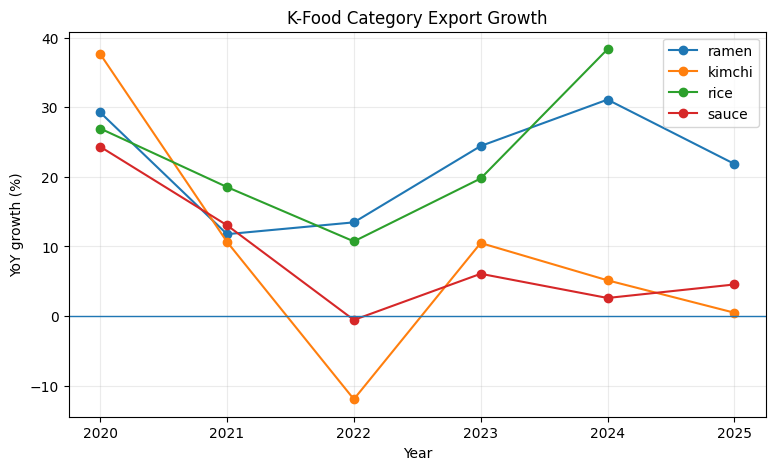

In [2]:
plt.figure(figsize=(9,5))
for c in ["ramen_yoy","kimchi_yoy","rice_yoy","sauce_yoy"]:
    plt.plot(category.year,category[c],marker="o",label=c.replace("_yoy",""))
plt.axhline(0,linewidth=1)
plt.title("K-Food Category Export Growth")
plt.xlabel("Year"); plt.ylabel("YoY growth (%)"); plt.legend(); plt.grid(alpha=.25); plt.show()


# 4. Company product-exposure map

\[
CompanyDemand_{i,t}=\sum_c Exposure_{i,c}	imes CategorySignal_{c,t}
\]

The weights are analyst priors informed by public product mix, **not reported exact category revenue shares**. This is why exposure sensitivity is tested later.


In [3]:
exposure.round(2)

,broad,ramen,kimchi,rice,sauce
company,,,,,
Samyang Foods,0.07,0.90,0.00,0.00,0.03
Nongshim,0.17,0.80,0.00,0.00,0.03
CJ CheilJedang,0.58,0.02,0.08,0.20,0.12
Daesang,0.13,0.02,0.40,0.02,0.43
Ottogi,0.25,0.42,0.01,0.07,0.25
Pulmuone,0.78,0.08,0.01,0.10,0.03


# 5. U.S.-specific overlay and H Mart

The historical core is **not falsely described as a pure U.S. factor** because a complete open annual U.S.-by-category panel is unavailable.

Current U.S. evidence is used separately:
- U.S. Korean agri-food exports rose from about $1.593B in 2024 to $1.804B in 2025.
- U.S. ramyeon exports rose from about $215.6M to $254.7M.
- U.S. sauce exports rose about 5%.
- H Mart reportedly expanded from roughly 77 stores to around 100 in about three years.

H Mart's roughly $2B reported annual sales are **not used as a historical factor** because there is no audited public annual series.


In [4]:
us=pd.DataFrame({
"metric":["U.S. total K-food","U.S. ramyeon","U.S. sauce","H Mart store footprint"],
"growth_pct":[(1803.5/1592.9-1)*100,(254.7/215.6-1)*100,5.0,((100/77)**(1/3)-1)*100]})
us["signal"]=np.tanh(us.growth_pct/20)
us.round(3)


,metric,growth_pct,signal
0,U.S. total K-food,13.221,0.579
1,U.S. ramyeon,18.135,0.720
2,U.S. sauce,5.000,0.245
3,H Mart store footprint,9.103,0.426


# 6. Equity lead test

For formation year \(t\), the category-demand score is compared with next-calendar-year company price return minus KOSPI.

**Critical timing caveat:** annual customs data are finalized shortly after year-end. Therefore this is a **lead-association test**, not a fully executable January-1 backtest. A real backtest must start after each release timestamp using daily/monthly prices.


In [5]:
panel=[]
for y in range(2020,2025):
    sc=score_for_year(y)
    tgt=returns.loc[returns.year.eq(y+1)].iloc[0]
    prev=returns.loc[returns.year.eq(y)].iloc[0]
    for co in exposure.index:
        panel.append({"formation_year":y,"target_year":y+1,"company":co,
                      "score":sc[co],"excess":tgt[co]-tgt.KOSPI,
                      "prior_return":prev[co]})
panel=pd.DataFrame(panel)

eqrows=[]
for y,g in panel.groupby("target_year"):
    ric=spearmanr(g.score,g.excess).statistic
    pic=pearsonr(g.score,g.excess).statistic
    long_=g.nlargest(2,"score").excess.mean()
    short_=g.nsmallest(2,"score").excess.mean()
    eqrows.append([y,ric,pic,long_,short_,long_-short_])
eq=pd.DataFrame(eqrows,columns=["year","rank_ic","pearson_ic","long_excess","short_excess","long_short"])
eq.round(3)


,year,rank_ic,pearson_ic,long_excess,short_excess,long_short
0,2021,-0.314,-0.435,-12.040,-0.57,-11.470
1,2022,-0.714,-0.654,6.335,47.90,-41.565
2,2023,0.486,0.600,23.315,-28.78,52.095
3,2024,0.257,0.659,132.660,0.06,132.600
4,2025,0.600,0.564,-37.350,-80.08,42.730


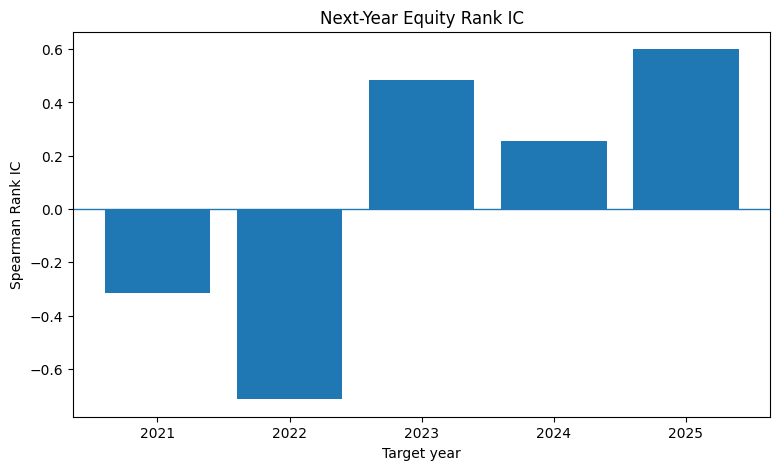

In [6]:
plt.figure(figsize=(9,5))
plt.bar(eq.year.astype(str),eq.rank_ic)
plt.axhline(0,linewidth=1)
plt.title("Next-Year Equity Rank IC")
plt.xlabel("Target year"); plt.ylabel("Spearman Rank IC"); plt.show()


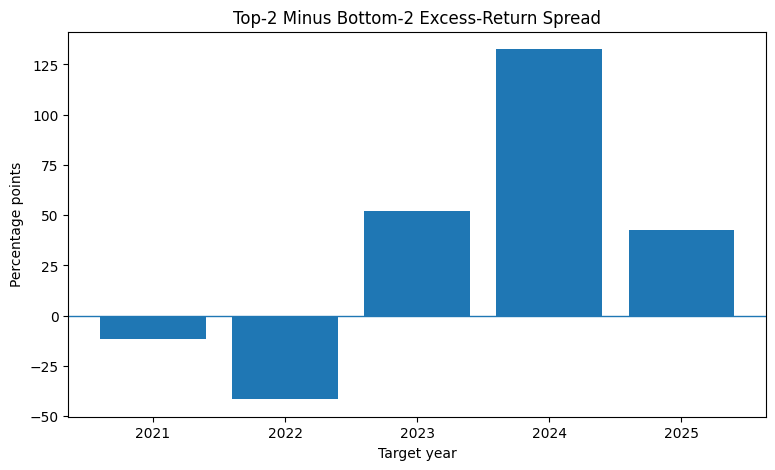

In [7]:
plt.figure(figsize=(9,5))
plt.bar(eq.year.astype(str),eq.long_short)
plt.axhline(0,linewidth=1)
plt.title("Top-2 Minus Bottom-2 Excess-Return Spread")
plt.xlabel("Target year"); plt.ylabel("Percentage points"); plt.show()


## Equity interpretation

The 2023–2025 results are directionally strong, but the 2021–2022 years are negative. The full-period mean Rank IC is therefore weak.

The visually large long-short spread must not be read as a proven Sharpe ratio: the sample has only five annual periods and the 2024 result is heavily influenced by Samyang's extraordinary return.


# 7. Fundamental lead test

A consumer-demand signal should first transmit into fundamentals:

\[
DemandScore_{i,t}ightarrow SalesGrowth_{i,t+1}
\]

CJ uses Food-division sales rather than total-company sales to reduce contamination from non-food businesses.


In [8]:
fund=[]
for y in range(2021,2025):
    sc=score_for_year(y)
    tgt=sales.loc[sales.year.eq(y+1)].iloc[0]
    for co in exposure.index:
        fund.append({"formation_year":y,"target_year":y+1,"company":co,
                     "score":sc[co],"sales_growth":tgt[co+"_growth"]})
fund=pd.DataFrame(fund)
rows=[]
for y,g in fund.groupby("target_year"):
    rows.append([y,spearmanr(g.score,g.sales_growth).statistic,
                 pearsonr(g.score,g.sales_growth).statistic])
fmetrics=pd.DataFrame(rows,columns=["year","rank_ic","pearson_ic"])
fmetrics.round(3)


,year,rank_ic,pearson_ic
0,2022,-0.886,-0.582
1,2023,1.000,0.722
2,2024,0.200,0.588
3,2025,0.486,0.575


The fundamental relationship is more encouraging after the pandemic-normalization period, but it is still regime-sensitive. It is more defensible to describe the model as a **candidate fundamental nowcast** than as a proven stock-price factor.


# 8. Robustness: Samyang removal, sauce exclusion, momentum control

In [9]:
# Remove Samyang
ex=panel[panel.company!="Samyang Foods"]
exrows=[]
for y,g in ex.groupby("target_year"):
    exrows.append([y,spearmanr(g.score,g.excess).statistic,
                   g.nlargest(1,"score").excess.mean()-g.nsmallest(1,"score").excess.mean()])
exres=pd.DataFrame(exrows,columns=["year","rank_ic","long_short"])

# Remove sauce factor
ns=[]
for y in range(2020,2025):
    sc=score_for_year(y,include_sauce=False)
    tgt=returns.loc[returns.year.eq(y+1)].iloc[0]
    for co in exposure.index:
        ns.append({"year":y+1,"company":co,"score":sc[co],"excess":tgt[co]-tgt.KOSPI})
ns=pd.DataFrame(ns)
ns_ic=[spearmanr(g.score,g.excess).statistic for _,g in ns.groupby("year")]

# Momentum control
m=smf.ols("excess ~ score + prior_return + C(target_year)",data=panel).fit()

pd.DataFrame({
"metric":["Mean Rank IC","Mean L/S spread","Mean Rank IC ex-Samyang",
          "Mean L/S ex-Samyang","Mean Rank IC no sauce","Score coef with momentum control",
          "Score p-value with momentum control"],
"value":[eq.rank_ic.mean(),eq.long_short.mean(),exres.rank_ic.mean(),
         exres.long_short.mean(),np.mean(ns_ic),m.params["score"],m.pvalues["score"]]
}).round(4)


,metric,value
0,Mean Rank IC,0.0629
1,Mean L/S spread,34.8780
2,Mean Rank IC ex-Samyang,-0.1200
3,Mean L/S ex-Samyang,-2.7780
4,Mean Rank IC no sauce,0.0971
5,Score coef with momentum control,79.4484
6,Score p-value with momentum control,0.1440


The most important robustness result is the **Samyang removal test**. If the sector factor collapses without one exceptional winner, the evidence is insufficient for a general K-food equity-alpha claim.


# 9. Permutation placebo

Scores are shuffled across companies within each year while returns and year structure remain unchanged. This directly asks whether the observed mapping is unusual versus random rankings.


In [10]:
def fast_spearman(a,b):
    ra=pd.Series(a).rank().to_numpy()
    rb=pd.Series(b).rank().to_numpy()
    return float(np.corrcoef(ra,rb)[0,1])

groups=[]
for y,g in panel.groupby("target_year"):
    groups.append((y,g.score.to_numpy(),g.excess.to_numpy()))

actual_ic=np.mean([fast_spearman(s,e) for _,s,e in groups])
actual_ls=np.mean([e[np.argsort(s)[-2:]].mean()-e[np.argsort(s)[:2]].mean() for _,s,e in groups])

rng=np.random.default_rng(42)
nperm=2000
pi=[]; pl=[]
for _ in range(nperm):
    ii=[]; ll=[]
    for _,s,e in groups:
        sp=rng.permutation(s)
        ii.append(fast_spearman(sp,e))
        o=np.argsort(sp)
        ll.append(e[o[-2:]].mean()-e[o[:2]].mean())
    pi.append(np.mean(ii)); pl.append(np.mean(ll))
pi=np.array(pi); pl=np.array(pl)
p_ic=(np.sum(np.abs(pi)>=abs(actual_ic))+1)/(nperm+1)
p_ls=(np.sum(np.abs(pl)>=abs(actual_ls))+1)/(nperm+1)
pd.DataFrame({"metric":["Actual mean IC","IC placebo p","Actual mean L/S","L/S placebo p"],
              "value":[actual_ic,p_ic,actual_ls,p_ls]}).round(4)


,metric,value
0,Actual mean IC,0.0629
1,IC placebo p,0.7441
2,Actual mean L/S,34.8780
3,L/S placebo p,0.1354


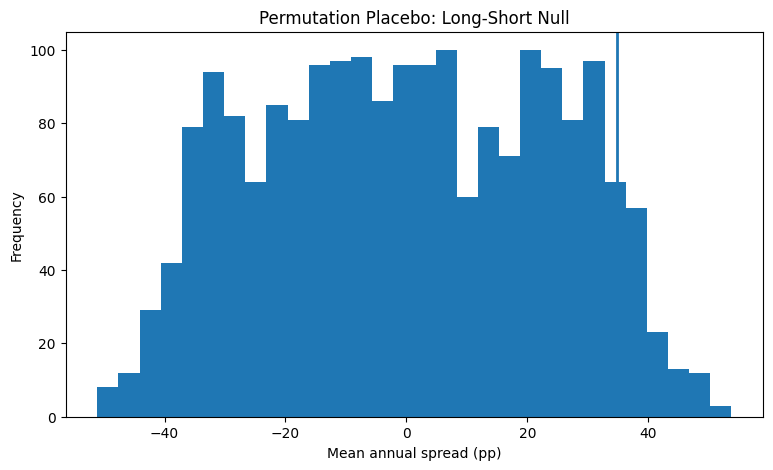

In [11]:
plt.figure(figsize=(9,5))
plt.hist(pl,bins=30)
plt.axvline(actual_ls,linewidth=2)
plt.title("Permutation Placebo: Long-Short Null")
plt.xlabel("Mean annual spread (pp)"); plt.ylabel("Frequency"); plt.show()


The placebo p-values do not establish conventional statistical significance. This is a key reason the paper does not claim robust alpha.


# 10. Exposure-weight sensitivity

Because exact historic category revenue shares are not public for every company, 1,000 plausible perturbations around the analyst exposure matrix are tested.


In [12]:
base=exposure[cats].to_numpy(dtype=float)
names=list(exposure.index)
sig_by_year={y:category.loc[category.year.eq(y),[c+"_sig" for c in cats]].iloc[0].to_numpy() for y in range(2020,2025)}
exc_by_year={y:panel[panel.target_year.eq(y)].set_index("company").loc[names,"excess"].to_numpy() for y in range(2021,2026)}
rng=np.random.default_rng(123)
sims=[]
for _ in range(1000):
    samp=np.vstack([rng.dirichlet(row*80+0.15) for row in base])
    ii=[]; ll=[]
    for y in range(2020,2025):
        scores=samp.dot(sig_by_year[y])
        exc=exc_by_year[y+1]
        ii.append(fast_spearman(scores,exc))
        o=np.argsort(scores)
        ll.append(exc[o[-2:]].mean()-exc[o[:2]].mean())
    sims.append([np.mean(ii),np.mean(ll)])
sims=pd.DataFrame(sims,columns=["mean_ic","mean_ls"])
sims.describe(percentiles=[.05,.5,.95]).round(4)


,mean_ic,mean_ls
count,1000.0000,1000.0000
mean,0.0658,34.2908
std,0.0432,2.3366
min,-0.0629,28.7130
5%,-0.0057,30.9260
50%,0.0629,34.8780
95%,0.1429,36.6880
max,0.2229,40.5490


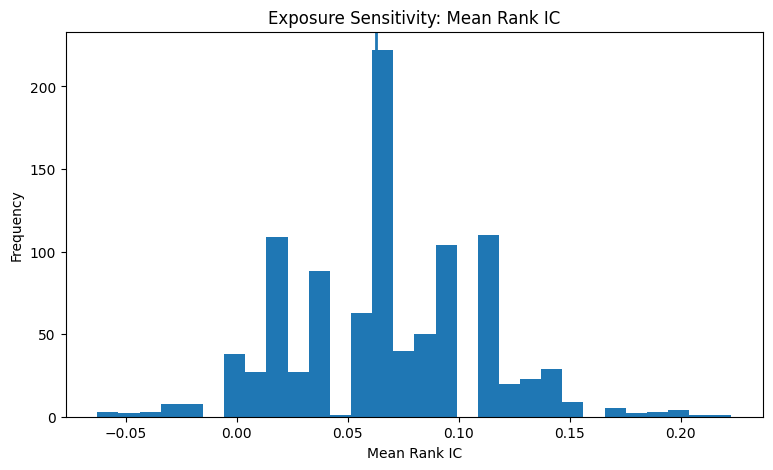

In [13]:
plt.figure(figsize=(9,5))
plt.hist(sims.mean_ic,bins=30)
plt.axvline(sims.mean_ic.median(),linewidth=2)
plt.title("Exposure Sensitivity: Mean Rank IC")
plt.xlabel("Mean Rank IC"); plt.ylabel("Frequency"); plt.show()


Exposure perturbations do not radically change the basic ordering, which is helpful. But robustness to weights is **not** the same as statistical significance; the small sample remains the dominant issue.


# 11. Regime dependence

In [14]:
pd.DataFrame({
"period":["2021-2025","2023-2025"],
"mean_rank_ic":[eq.rank_ic.mean(),eq[eq.year>=2023].rank_ic.mean()],
"mean_ls_spread":[eq.long_short.mean(),eq[eq.year>=2023].long_short.mean()]
}).round(3)


,period,mean_rank_ic,mean_ls_spread
0,2021-2025,0.063,34.878
1,2023-2025,0.448,75.808


Two interpretations must remain open:
1. K-food became a genuinely different mainstream-globalization regime after 2022.
2. Three positive years inside a five-year sample are simply small-sample luck.

The current data cannot distinguish those stories reliably.


# 12. Bias audit

- **Look-ahead:** deterministic transforms and t→t+1 structure reduce leakage; exact release-date returns are still required for an executable backtest.
- **Survivorship:** the current listed-company universe is selected ex post.
- **Exposure look-ahead:** static structural product weights are assumptions; sensitivity testing reduces but does not eliminate this weakness.
- **Export ≠ consumption:** inventory builds and distributor timing can distort exports.
- **Local production:** Nongshim and others manufacture overseas, so Korean exports understate local consumption.
- **Price-return bias:** annual variations exclude dividends.
- **Small N:** 5 equity years × 6 companies is far below institutional standards.
- **Classification:** sauce definitions differ across public datasets; this is explicitly ablated.
- **Multiple testing:** no p-hacking or return-optimized weighting is used.


# 13. Production research architecture

The next dataset should be monthly or weekly:

### Demand
- U.S. HS-code imports from Korea by product
- import volume, value and unit value
- Google Trends
- TikTok/YouTube/Reddit mention velocity and unique-creator breadth
- Amazon/Walmart/Instacart rank/review velocity
- grocery scanner / SKU velocity
- restaurant-menu penetration

### Distribution
- H Mart / 99 Ranch / Costco / Walmart doors and SKUs
- new-store/new-door additions
- local U.S. factory capacity and utilization

### Company / market controls
- historical category and geographic revenue shares
- analyst revisions
- momentum, value, size, quality, beta, liquidity
- company-specific commodity baskets and hedge timing
- KRW/USD

Then estimate:

\[
RevenueSurprise_{i,t+1}=f(Demand,Distribution,Pricing,FX,Commodity)
\]

followed by:

\[
ExcessReturn_{i,t+1}=\alpha+\beta_1\widehat{RevenueSurprise}+\beta_2Momentum+\beta_3Value+\beta_4Revisions+\epsilon
\]

This separates consumer demand from fundamental transmission and market pricing.


# 14. Final verdict

**Research idea:** strong and worth pursuing.

**Current open-source annual evidence:** insufficient to claim sector-wide hedge-fund alpha.

What survives:
- category demand cycles are measurable;
- company exposure mapping is economically coherent;
- post-2022 results are stronger;
- fundamental prediction is more promising than raw price prediction;
- U.S. trade/distribution evidence supports continued structural demand.

What fails:
- full-period Rank IC is weak;
- the attractive equity spread is heavily Samyang-dependent;
- placebo tests do not reject randomness at standard thresholds.

### Recommended title

**Can Alternative Consumer Data Predict Korean Food Equities? Building a U.S. K-Food Demand Nowcasting Factor**

The right next step is **better point-in-time monthly data, not more tuning of this annual model.**


# 15. Source register

Primary sources include MAFRA, Korea Customs Service, company IR/filings, FRED/IMF, and Pulmuone/Nongshim/CJ/Samyang disclosures. MarketScreener is used for reproducible annual price variations and some financial histories. H Mart is used only as a structural distribution proxy from press reporting.

See the accompanying `kfood_source_register_v3.csv` for the data-quality register.
